# Super Typhoon Bavi (July 2026): AI-Model Forecast and Verification

One ECMWF IFS operational analysis (2026-07-06 12 UTC) initializes three AI weather models for a 120-hour, 6-hourly forecast of Super Typhoon Bavi toward its expected landfall near Wenzhou, China (28.0° N, 120.7° E). NVIDIA's SFNO drives the `TCTrackerWuDuan` cyclone tracker for the storm's path and intensity (minimum sea-level pressure and maximum 10 m wind); ECMWF's AIFS2 and Google DeepMind's GraphCast (operational) provide 10 m wind and precipitation, and AIFS2 is also tracked to give a second path for comparison. The SFNO track is verified against the IBTrACS best track; wind and rain are shown as forecast products and are not scored. You will learn how to run a cyclone tracker inside an [Earth2Studio](https://github.com/NVIDIA/earth2studio) forecast loop, compare wind and rain from two models, and score a forecast track against observations.

> **Measured on an NVIDIA L40:** 8 min runtime · 36.9 GiB peak GPU memory.

1. Setup
2. SFNO track and intensity
3. AIFS2 and GraphCast forecasts
4. Precipitation
5. Storm tracks
6. 10 m wind
7. Forecast at Wenzhou
8. Verify against the IBTrACS best track

## 1 · Setup

Environment variables, imports, every setting a reader may change, and the data source for the initial condition. All three models start from the same IFS analysis, so their differences come from the models, not from their starting points.

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"  # GraphCast runs on JAX: allocate on demand so it shares the GPU with torch

In [2]:
import gc
from datetime import datetime, timedelta, date
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from tqdm.auto import tqdm

from earth2studio.models.px import SFNO, AIFS2, GraphCastOperational
from earth2studio.models.dx import TCTrackerWuDuan
from earth2studio.data import IFS, fetch_data
from earth2studio.utils.coords import map_coords
from earth2studio.utils.time import to_time_array
import earth2studio.run as run
from earth2studio.io import ZarrBackend

from ibtracs import load_best_track, verify_track
from metrics import haversine_km

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, torch.cuda.get_device_name() if torch.cuda.is_available() else "")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)

 Error Loading numa symbols, please install libnuma to avoid any performance issues
CuPy distance computation test failed with error: cuVS >= 24.12 or pylibraft < 24.12 should be installed to use this feature
device: cuda NVIDIA L40


In [3]:
# ---- forecast configuration ----
START_TIME = datetime(2026, 7, 6, 12)     # ECMWF IFS analysis cycle
NSTEPS     = 20                            # 120 h / 6 h
STEP_HOURS = 6
LANDFALL   = datetime(2026, 7, 11, 0)      # expected Wenzhou coast arrival

CITIES           = {"Wenzhou": (28.0, 120.7), "Taipei": (25.0, 121.6)}  # name -> (lat, lon)
WENZHOU          = CITIES["Wenzhou"]       # landfall target
STORM_SEARCH_BOX = {"lat": (5.0, 35.0), "lon": (115.0, 150.0)}

# plot extents [lon_min, lon_max, lat_min, lat_max] on the 0-360 grid
TRACK_EXTENT  = [120.0, 150.0, 8.0, 32.0]
PRECIP_EXTENT = [115.0, 150.0, 8.0, 33.0]

MS_TO_KMH = 3.6                                                    # wind unit conversion
PRECIP_LEVELS = [1, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300]     # daily mm
TOTAL_LEVELS  = [10, 25, 50, 75, 100, 150, 200, 300, 400, 600]     # storm-total mm
# km/h levels from m/s thresholds (gale 17, typhoon 33, ...)
WIND_LEVELS   = [round(v * MS_TO_KMH) for v in (0, 10, 17, 25, 33, 42, 50, 58, 65)]  # km/h
PVARS = np.array(["u10m", "v10m", "tp06"])                          # requested from precip models

PRECIP_CMAP = plt.cm.rainbow_r   # red = light rain -> blue-purple = heavy rain (house style)

PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUT_DIR = Path("outputs/bavi"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");      FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

VALID_TIMES = [START_TIME + timedelta(hours=STEP_HOURS * k) for k in range(NSTEPS + 1)]
FCST_WINDOW = f"{VALID_TIMES[0]:%Y-%m-%d} to {VALID_TIMES[-1]:%Y-%m-%d}"

def fig_title(models, when):
    """Figure title naming the model(s), the initialization time and the valid period."""
    return f"{models} | Init: {START_TIME:%Y-%m-%d %HZ} | {when}"

def mark_cities(ax, cities=CITIES, star_color="red", text_color="black"):
    """Draw a labeled star for each city on a cartopy map."""
    for name, (lat, lon) in cities.items():
        ax.plot(lon, lat, marker="*", color=star_color, ms=14, transform=ccrs.PlateCarree())
        ax.text(lon + 0.4, lat + 0.4, name, color=text_color, fontsize=9, fontweight="bold",
                ha="left", va="bottom", transform=ccrs.PlateCarree())

print("init:", START_TIME, "-> valid through", VALID_TIMES[-1],
      f"({(LANDFALL - START_TIME).total_seconds()/3600:.0f} h to expected landfall)")

init: 2026-07-06 12:00:00 -> valid through 2026-07-11 12:00:00 (108 h to expected landfall)


In [4]:
# One IFS analysis initializes all three models. ECMWF's own open-data server keeps only the last 4 days,
# so an archived cycle like this one comes from the AWS mirror (earth2studio's default source).
data = IFS(source="aws")

## 2 · SFNO track and intensity

SFNO steps the atmosphere forward 6 hours at a time, and after every step the Wu–Duan tracker finds cyclone centers in the vorticity field and links them into paths (following the [Earth2Studio cyclone-tracking example](https://nvidia.github.io/earth2studio/0.20.0/examples/02_medium_range/05_cyclone_tracking/)). This gives the storm's path, minimum sea-level pressure and maximum 10 m wind directly from the model fields.

In [5]:
# SFNO -> TCTrackerWuDuan (manual iterator loop, per the earth2studio example).
# SFNO is natively on the 721-lat grid like the tracker/IFS data, so no regrid is needed.
try:
    tracker    = TCTrackerWuDuan()
    prognostic = SFNO.load_model(SFNO.load_default_package()).to(DEVICE)
    tracker.reset_path_buffer()

    x, coords = fetch_data(
        source=data,
        time=to_time_array([START_TIME]),
        variable=prognostic.input_coords()["variable"],
        lead_time=prognostic.input_coords()["lead_time"],
        device=DEVICE,
    )

    output = None
    for step, (x, coords) in enumerate(
        tqdm(prognostic.create_iterator(x, coords), total=NSTEPS + 1, desc="SFNO+tracker")
    ):
        x, coords = map_coords(x, coords, tracker.input_coords())   # subselect tracker vars (grids already match at 721)
        output, output_coords = tracker(x, coords)
        if step == NSTEPS:
            break

    torch.save(output.cpu(), OUT_DIR / "track_sfno.pt")
    tracks = np.squeeze(output.cpu().numpy())
finally:
    free_gpu("tracker", "prognostic", "x", "coords", "output", "output_coords")

# squeeze drops the singleton (time, lead_time) dims -> [path, step, var], but also eats
# `path` when only one system is detected, so restore it here.
if tracks.ndim == 2:
    tracks = tracks[None]

In [6]:
def path_dataframe(tracks, p):
    """Tracker path `p` as a table: lead time, center lat/lon, min MSLP (hPa) and max 10 m wind (m/s); gaps dropped."""
    lat, lon = tracks[p, :, 0], tracks[p, :, 1]
    df = pd.DataFrame({
        "lead_time_h": np.arange(lat.shape[0]) * STEP_HOURS,
        "tclat": lat, "tclon": lon,
        "tcmsl_hPa": tracks[p, :, 2] / 100.0,   # Pa -> hPa
        "tcw10m_ms": tracks[p, :, 3],
    })
    return df.dropna(subset=["tclat", "tclon"]).reset_index(drop=True)

def select_best_path(tracks):
    """Pick Bavi among the detected systems and return (score, path index, table).

    Score = 2 x fraction of time inside the search box + track length - distance from Wenzhou at the end / 2000 km.
    """
    box = STORM_SEARCH_BOX
    candidates = []
    for p in range(tracks.shape[0]):
        df = path_dataframe(tracks, p)
        if len(df) < 3:
            continue
        frac_in = (df.tclat.between(*box["lat"]) & df.tclon.between(*box["lon"])).mean()
        d_final = haversine_km(df.tclat.iloc[-1], df.tclon.iloc[-1], *WENZHOU)
        score = 2.0 * frac_in + len(df) / (NSTEPS + 1) - d_final / 2000.0
        candidates.append((score, p, df))
    candidates.sort(key=lambda t: t[0], reverse=True)
    return candidates[0]

score, best_p, track_df = select_best_path(tracks)
print(f"selected path {best_p} of {tracks.shape[0]} detected  (score {score:.2f}, {len(track_df)} points)")
track_df.set_index("lead_time_h").to_xarray().to_netcdf(OUT_DIR / "track_sfno.nc")
track_df

selected path 2 of 18 detected  (score 2.88, 21 points)


,lead_time_h,tclat,tclon,tcmsl_hPa,tcw10m_ms
0,0,15.351907,142.861892,942.232500,44.845573
1,6,15.907433,141.263388,953.612891,29.225338
2,12,16.036672,139.805171,955.895547,28.574875
3,18,16.406763,138.533946,953.070078,28.638367
4,24,16.528051,137.201328,953.599687,29.061127
5,30,16.847867,135.938414,950.648047,29.029846
6,36,17.047714,134.605340,952.160313,29.213362
7,42,17.379761,133.439784,948.274766,30.573652
8,48,17.672948,132.320936,950.106484,29.137764
9,54,18.133731,131.127569,947.290625,29.639967


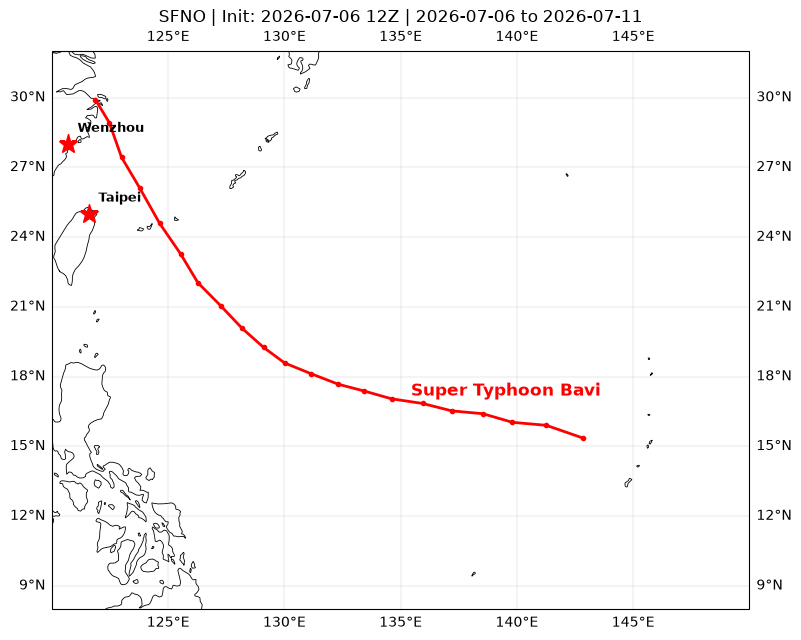

In [7]:
fig = plt.figure(figsize=(9, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(TRACK_EXTENT, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)

# only Bavi's track — the tracker's other detected systems are different storms, not shown
ax.plot(track_df.tclon, track_df.tclat, "-o", color="red", lw=2.0, ms=3,
        transform=ccrs.PlateCarree())
# name the storm inline on the map (clearer than a legend entry)
anchor = track_df.iloc[len(track_df) // 3]
ax.text(anchor.tclon + 2.0, anchor.tclat, "Super Typhoon Bavi",
        color="red", fontsize=12, fontweight="bold",
        ha="left", va="center", transform=ccrs.PlateCarree())
mark_cities(ax)

ax.set_title(fig_title("SFNO", FCST_WINDOW))
fig.savefig(FIG_DIR / "track.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** the red line is the SFNO storm center every 6 hours from the initial time; red stars mark Wenzhou and Taipei. Look at where the track meets the coast relative to Wenzhou. Only Bavi's path is drawn; the tracker's other detections are different weather systems. Bavi is picked from the detections by path length, by how much of the path lies in the search box and by where it ends relative to Wenzhou, so the choice uses knowledge of where the storm went; the lead-0 row in section 8 shows how far the chosen path starts from the best track.

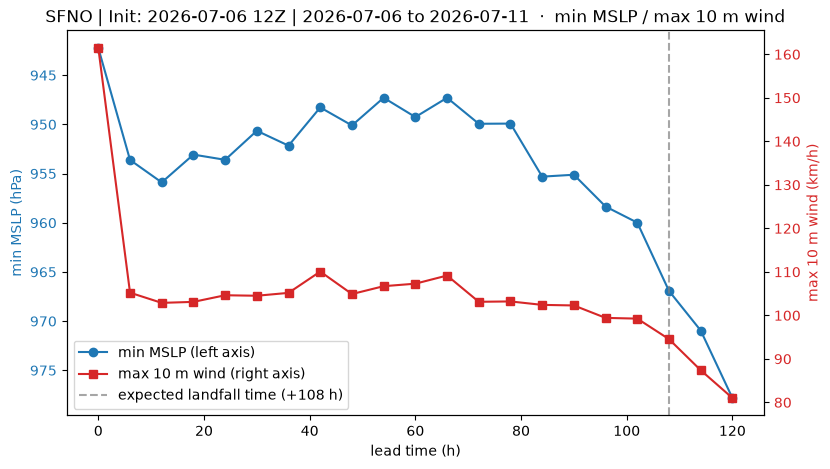

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 5))
(mslp_line,) = ax1.plot(track_df.lead_time_h, track_df.tcmsl_hPa, "-o", color="tab:blue", label="min MSLP (left axis)")
ax1.set_xlabel("lead time (h)"); ax1.set_ylabel("min MSLP (hPa)", color="tab:blue")
ax1.invert_yaxis()                                # deeper (stronger) points upward
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
(wind_line,) = ax2.plot(track_df.lead_time_h, track_df.tcw10m_ms * MS_TO_KMH, "-s", color="tab:red",
                        label="max 10 m wind (right axis)")
ax2.set_ylabel("max 10 m wind (km/h)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

landfall_h = (LANDFALL - START_TIME).total_seconds() / 3600
landfall_line = ax1.axvline(landfall_h, color="gray", ls="--", alpha=0.7,
                            label=f"expected landfall time (+{landfall_h:.0f} h)")
ax1.legend(handles=[mslp_line, wind_line, landfall_line], loc="lower left")
ax1.set_title(fig_title("SFNO", FCST_WINDOW) + "  ·  min MSLP / max 10 m wind")
fig.savefig(FIG_DIR / "intensity.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** blue is the minimum sea-level pressure (left axis, inverted so a deeper, stronger storm plots higher) and red is the maximum 10 m wind (right axis, km/h), both taken from the SFNO fields along the tracked path. The dashed line marks the expected landfall time from the configuration. The first point (+0 h) is the IFS analysis, not a forecast, so the model's own intensity starts at +6 h and the change between the first two points shows how the model adjusts the analysis. A 0.25° model cannot resolve the inner core of an intense typhoon, so expect it to be weaker than the real storm; section 8 compares the pressure with IBTrACS.

## 3 · AIFS2 and GraphCast forecasts

AIFS2 and GraphCast (operational) run from the same IFS analysis and save 10 m wind and 6-hour precipitation to Zarr for the maps below. AIFS2 also drives the Wu–Duan tracker, which gives a second track to compare with SFNO. Each model is loaded and run in turn. The two PyTorch models (AIFS2 and SFNO) are released from the GPU as soon as they finish; GraphCast runs on JAX, which keeps its GPU memory until the kernel is shut down, so it runs last. The first GraphCast call compiles its GPU kernels, which takes a few minutes and prints a "Very slow compile?" alarm; that is expected.

In [9]:
# AIFS2: 10 m wind + 6-hour precipitation to Zarr. Models run one at a time; free_gpu releases VRAM in `finally`.
aifs_zarr = str(OUT_DIR / "aifs2_ifs.zarr")
try:
    model = AIFS2.load_model(AIFS2.load_default_package())
    backend = ZarrBackend(aifs_zarr, backend_kwargs={"overwrite": True})
    run.deterministic([START_TIME], NSTEPS, model, data, backend,
                      output_coords={"variable": PVARS}, device=DEVICE)
finally:
    free_gpu("model", "backend")

2026-11-01 06:33:05.232 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 06:33:05.232 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 06:33:11.759 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from IFS
2026-11-01 06:33:11.761 | INFO     | earth2studio.run:deterministic:162 - Inference starting!
2026-11-01 06:33:27.429 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


In [10]:
# AIFS2 -> TCTrackerWuDuan (same pattern as SFNO; also on the 721 grid, no regrid needed)
try:
    tracker    = TCTrackerWuDuan()
    prognostic = AIFS2.load_model(AIFS2.load_default_package()).to(DEVICE)
    tracker.reset_path_buffer()

    x, coords = fetch_data(
        source=data,
        time=to_time_array([START_TIME]),
        variable=prognostic.input_coords()["variable"],
        lead_time=prognostic.input_coords()["lead_time"],
        device=DEVICE,
    )

    output = None
    for step, (x, coords) in enumerate(
        tqdm(prognostic.create_iterator(x, coords), total=NSTEPS + 1, desc="AIFS2+tracker")
    ):
        x, coords = map_coords(x, coords, tracker.input_coords())
        output, output_coords = tracker(x, coords)
        if step == NSTEPS:
            break

    torch.save(output.cpu(), OUT_DIR / "track_aifs2.pt")
    tracks_aifs = np.squeeze(output.cpu().numpy())
finally:
    free_gpu("tracker", "prognostic", "x", "coords", "output", "output_coords")

if tracks_aifs.ndim == 2:            # single detected path -> [step, var]; restore the path axis
    tracks_aifs = tracks_aifs[None]

In [11]:
score_a, best_pa, track_aifs_df = select_best_path(tracks_aifs)
# AIFS2 zero-fills msl at step 0 -> NaN it out (daily boxes skip step 0 anyway)
track_aifs_df.loc[track_aifs_df.lead_time_h == 0, "tcmsl_hPa"] = np.nan
print(f"AIFS2: selected path {best_pa} of {tracks_aifs.shape[0]} detected  "
      f"(score {score_a:.2f}, {len(track_aifs_df)} points)")
track_aifs_df.set_index("lead_time_h").to_xarray().to_netcdf(OUT_DIR / "track_aifs2.nc")
track_aifs_df

AIFS2: selected path 2 of 16 detected  (score 2.90, 21 points)


,lead_time_h,tclat,tclon,tcmsl_hPa,tcw10m_ms
0,0,15.351907,142.861892,NaN,44.845573
1,6,15.758494,141.318985,947.258594,31.276531
2,12,15.971651,139.789186,947.668984,30.661482
3,18,16.224383,138.399854,946.127969,30.324329
4,24,16.455479,136.942753,944.889609,29.691944
5,30,16.625527,135.533206,944.149375,31.282564
6,36,16.758798,134.247198,946.208359,29.580030
7,42,16.915796,133.207178,941.220391,29.971039
8,48,17.138758,132.260342,942.141016,31.414078
9,54,17.615081,131.392581,941.957109,30.825830


In [12]:
# GraphCast (operational): 10 m wind + 6-hour precipitation to Zarr; free_gpu drops the Python references in `finally`; JAX keeps its GPU memory until the kernel exits.
gc_zarr = str(OUT_DIR / "graphcast_ifs.zarr")
try:
    model = GraphCastOperational.load_model(GraphCastOperational.load_default_package())
    backend = ZarrBackend(gc_zarr, backend_kwargs={"overwrite": True})
    run.deterministic([START_TIME], NSTEPS, model, data, backend,
                      output_coords={"variable": PVARS}, device=DEVICE)
finally:
    free_gpu("model", "backend")

2026-11-01 06:34:18.407 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 06:34:18.407 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 06:34:23.741 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from IFS
2026-11-01 06:34:23.742 | INFO     | earth2studio.run:deterministic:162 - Inference starting!


E1101 06:36:25.343655  135133 slow_operation_alarm.cc:74] 
********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************
E1101 06:38:05.969097  135130 slow_operation_alarm.cc:141] The operation took 3m40.625505489s

********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


2026-11-01 06:39:19.832 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


## 4 · Precipitation

Daily and storm-total rain from AIFS2 and GraphCast side by side, then the 6-hour rain at the SFNO storm center along its track. These are forecast products: no rain observations are used in this notebook.

In [13]:
def open_forecast(zarr_path):
    """Open a model's Zarr output as (lead_time, lat, lon) fields, dropping the single init-time dimension.

    Stops if the store was written for another start time or forecast length than the settings above,
    so a skipped or failed model cell can never be plotted under the wrong title."""
    ds = xr.open_zarr(zarr_path, consolidated=False)
    if "time" in ds.dims:
        init = pd.Timestamp(ds["time"].values[0])
        assert init == pd.Timestamp(START_TIME), f"{zarr_path} was written for init {init}, not {START_TIME}: re-run its cell"
        ds = ds.isel(time=0)
    assert ds.sizes["lead_time"] == NSTEPS + 1, f"{zarr_path} has {ds.sizes['lead_time']} lead times, expected {NSTEPS + 1}: re-run its cell"
    return ds

def daily_precip_mm(ds, day):
    """Rain (mm) summed over the 6-hour totals valid at 00, 06, 12 and 18 UTC on `day`; None if no step falls on it.

    tp06 at a valid time is the 6 hours ending then, so the sum covers 18 UTC the day before to 18 UTC on `day`.
    Step 0 is skipped because it carries no accumulation.
    """
    total = None
    for s in range(1, NSTEPS + 1):
        if VALID_TIMES[s].date() == day:
            layer = np.asarray(ds["tp06"].isel(lead_time=s)) * 1000.0
            total = layer if total is None else total + layer
    return None if total is None else np.clip(total, 0, None)

def total_precip_mm(ds):
    """Storm-total rain (mm) over the whole forecast; step 0 carries no accumulation and is skipped."""
    t = np.asarray(ds["tp06"].isel(lead_time=slice(1, NSTEPS + 1)).sum("lead_time")) * 1000.0
    return np.clip(t, 0, None)

def wind_speed(ds):
    """10 m wind speed in km/h, shape (lead, lat, lon)."""
    return np.hypot(np.asarray(ds["u10m"]), np.asarray(ds["v10m"])) * MS_TO_KMH

def peak_wind(ds):
    """Highest 10 m wind speed (km/h) at each grid point over all lead times."""
    return wind_speed(ds).max(axis=0)

def wind_at(ds, when):
    """10 m wind speed (km/h) at the forecast step closest to `when`."""
    s = int(round((when - START_TIME).total_seconds() / 3600 / STEP_HOURS))
    s = min(max(s, 0), NSTEPS)
    return wind_speed(ds)[s]

def domain_max(field2d):
    """Peak value inside PRECIP_EXTENT, so systems outside the plotted box are ignored."""
    iy = (LAT >= PRECIP_EXTENT[2]) & (LAT <= PRECIP_EXTENT[3])
    ix = (LON >= PRECIP_EXTENT[0]) & (LON <= PRECIP_EXTENT[1])
    return float(np.nanmax(field2d[np.ix_(iy, ix)]))

def plot_comparison(fieldA, fieldG, lon, lat, levels, cmap, title, save,
                    extent=PRECIP_EXTENT, units="mm"):
    """AIFS2 (left) and GraphCast (right) maps of one field on shared color bands; saves the figure to `save`."""
    norm = BoundaryNorm(levels, ncolors=cmap.N)  # one distinct color per band, even when bands are uneven
    fig, axes = plt.subplots(1, 2, figsize=(15, 6),
                             subplot_kw={"projection": ccrs.PlateCarree()})
    for ax, field, name in zip(axes, [fieldA, fieldG], ["AIFS2", "GraphCast"]):
        # values above the top level are clipped into the top band; below the lowest band stays blank
        im = ax.contourf(lon, lat, np.clip(field, None, levels[-1]), levels=levels, cmap=cmap, norm=norm,
                         transform=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.4)
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)
        mark_cities(ax)
        ax.set_title(name)
        map_colorbar(fig, ax, im, label=units, orientation="horizontal", ticks=levels)  # as long as the drawn map; label every band
    fig.suptitle(title, y=1.02, fontsize=13)
    fig.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

dsA = open_forecast(str(OUT_DIR / "aifs2_ifs.zarr"))
dsG = open_forecast(str(OUT_DIR / "graphcast_ifs.zarr"))
LON = np.asarray(dsA["lon"]); LAT = np.asarray(dsA["lat"])

# heavy full-grid reductions computed once, reused by both the maps and the summary
totalA, totalG = total_precip_mm(dsA), total_precip_mm(dsG)   # storm-total precip (mm)
peakA,  peakG  = peak_wind(dsA),       peak_wind(dsG)         # peak 10 m wind (km/h)

max daily precip: 2026-07-08


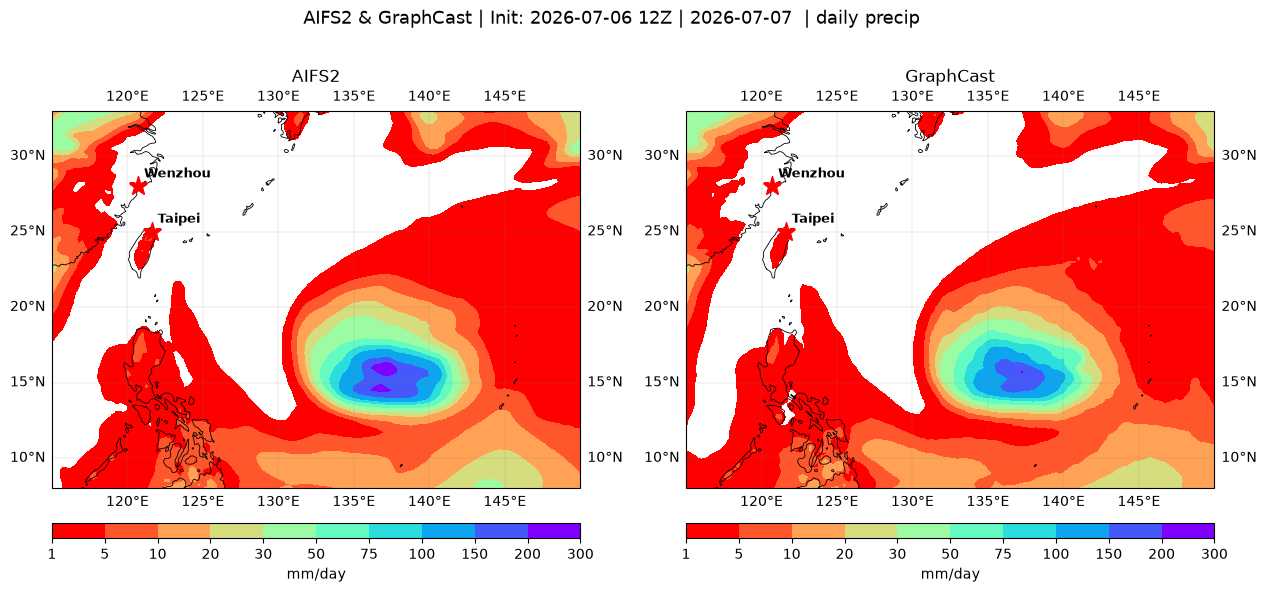

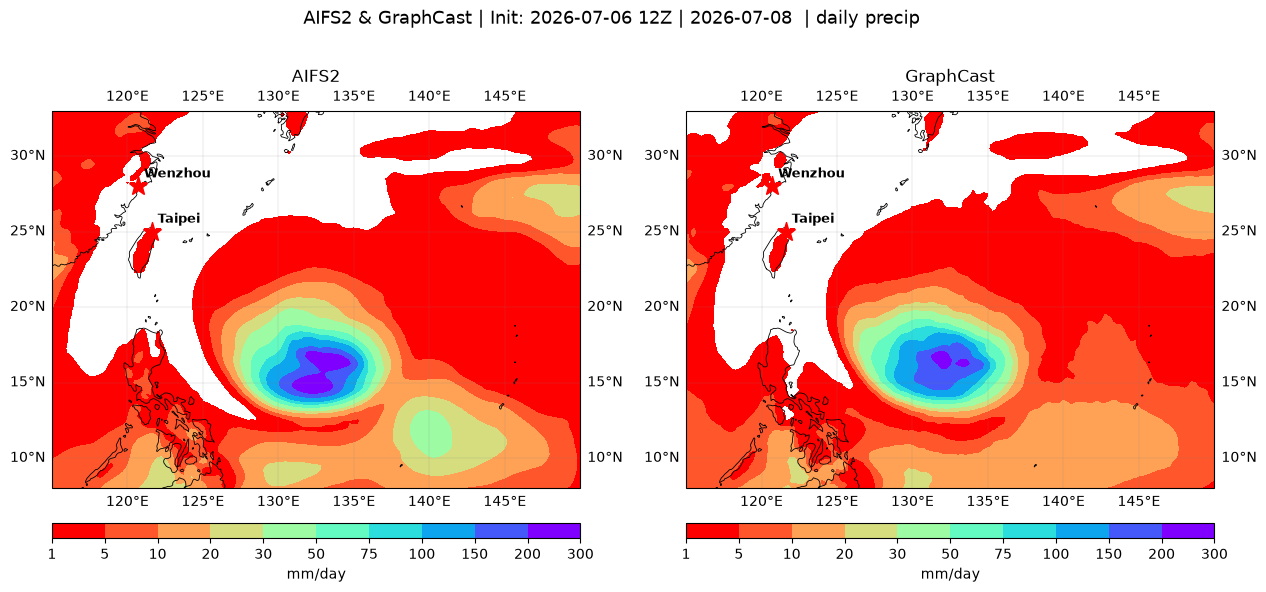

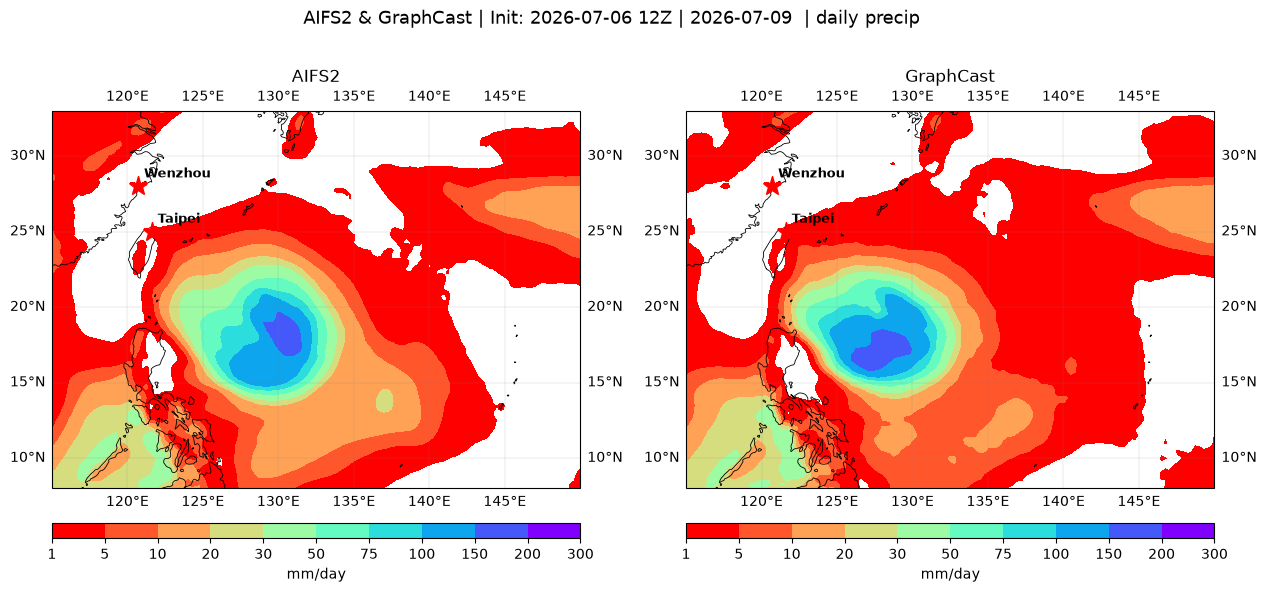

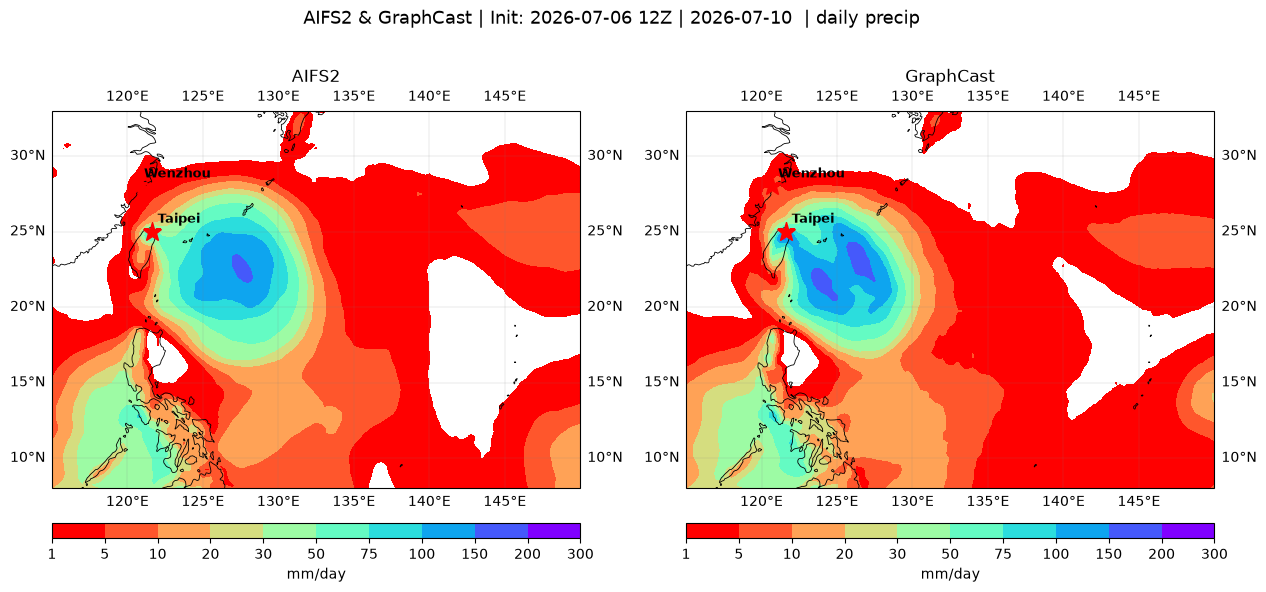

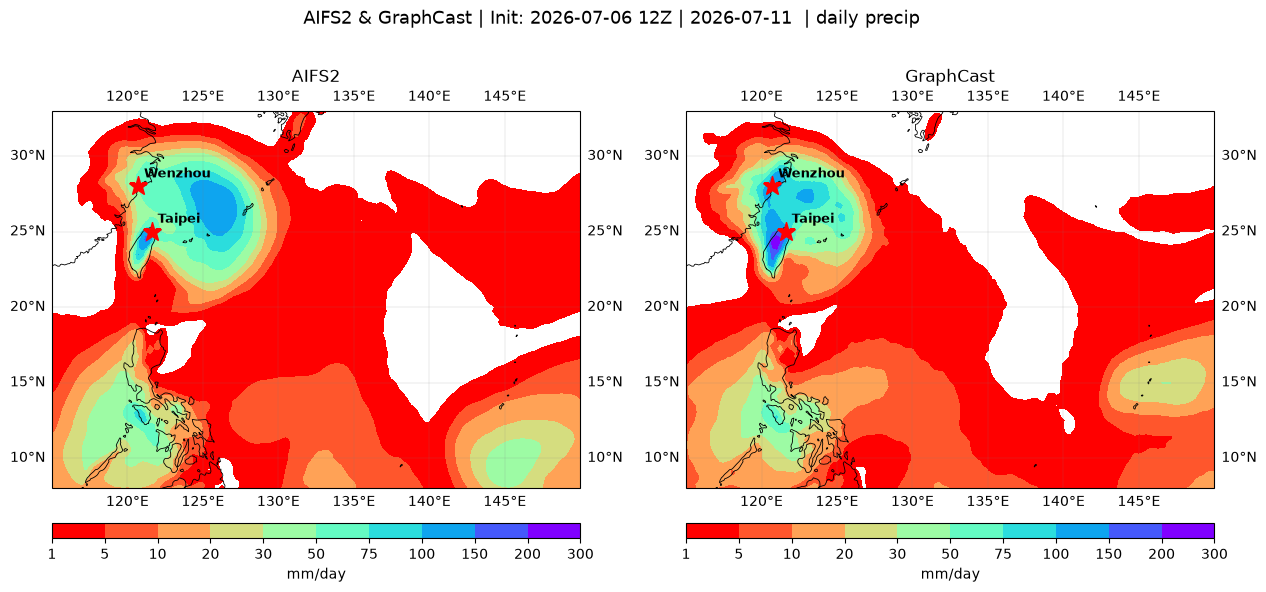

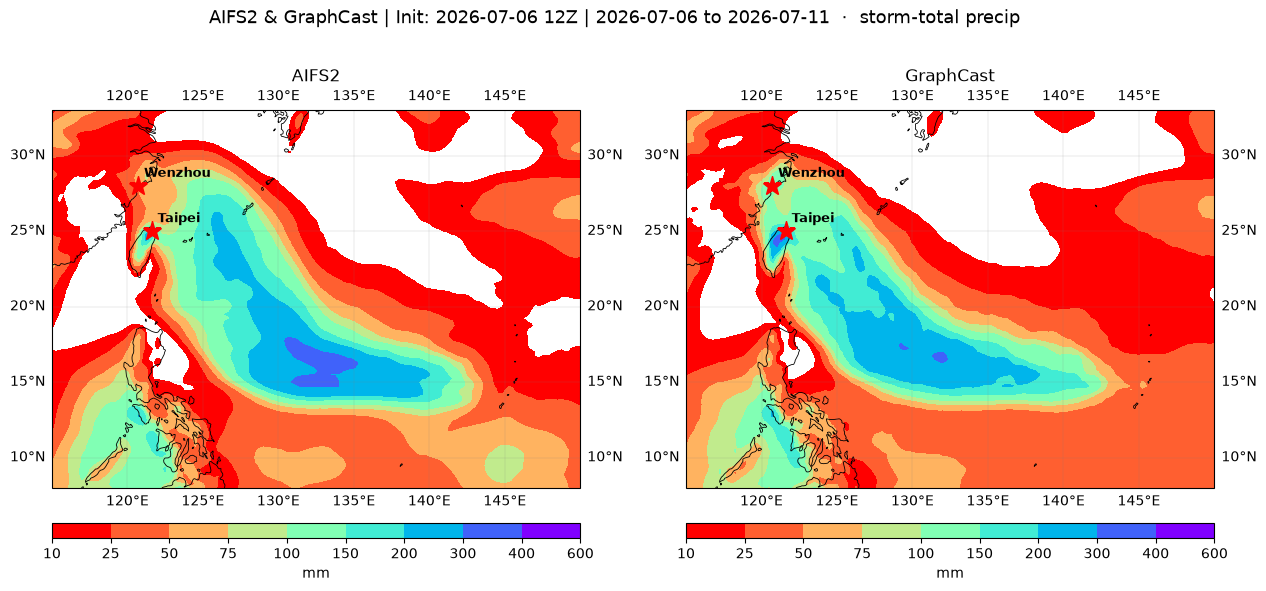

In [14]:
# daily precip fields for both models, then flag the day with the domain-peak accumulation
daily = {}
for day in [date(2026, 7, d) for d in (7, 8, 9, 10, 11)]:
    a, g = daily_precip_mm(dsA, day), daily_precip_mm(dsG, day)
    if a is not None and g is not None:
        daily[day] = (a, g)

max_precip_day = max(daily, key=lambda d: max(domain_max(daily[d][0]), domain_max(daily[d][1])))
print("max daily precip:", max_precip_day)

for day, (a, g) in daily.items():
    is_max = day == max_precip_day
    plot_comparison(a, g, LON, LAT, PRECIP_LEVELS, PRECIP_CMAP,
                    fig_title("AIFS2 & GraphCast", f"{day:%Y-%m-%d}") + ("  | daily precip "),
                    FIG_DIR / (f"precip_daily_{day}_max.png" if is_max else f"precip_daily_{day}.png"),
                    units="mm/day")

plot_comparison(totalA, totalG, LON, LAT, TOTAL_LEVELS, PRECIP_CMAP,
                fig_title("AIFS2 & GraphCast", FCST_WINDOW) + "  ·  storm-total precip",
                FIG_DIR / "precip_total.png", units="mm")

**How to read this:** each pair of maps puts AIFS2 (left) and GraphCast (right) on the same color bands, from red (light rain) to blue-purple (heavy rain); areas below the lowest band are left blank. A daily map adds the four 6-hour totals valid at 00, 06, 12 and 18 UTC on that date (so it covers 18 UTC the day before to 18 UTC). The last day's map holds only three 6-hour totals because the forecast ends at 12 UTC, and the rain from 12 to 18 UTC on the first day is in no daily map (it is in the storm total). The file of the day with the highest single-point total ends in `_max`. The storm-total map adds up the whole 120-hour forecast. Look at where the heaviest rain falls relative to the track and the coast, and whether the two models agree.

In [15]:
# ---- precipitation at each track time step (sampled at the storm center) ----
def precip_along_track(ds):
    """6-hour rain (mm) at the grid point nearest the SFNO storm center, for each tracked lead time."""
    out = []
    for _, r in track_df.iterrows():
        s  = int(r.lead_time_h // STEP_HOURS)
        iy = int(np.abs(LAT - r.tclat).argmin())
        ix = int(np.abs(LON - r.tclon).argmin())
        out.append(float(np.asarray(ds["tp06"].isel(lead_time=s))[iy, ix]) * 1000.0)
    return out

track_precip = pd.DataFrame({
    "valid":          [START_TIME + timedelta(hours=int(h)) for h in track_df.lead_time_h],
    "lead_h":         track_df.lead_time_h.values,
    "lat":            track_df.tclat.round(1).values,
    "lon":            track_df.tclon.round(1).values,
    "AIFS2_mm6h":     np.round(precip_along_track(dsA), 1),
    "GraphCast_mm6h": np.round(precip_along_track(dsG), 1),
})
print(track_precip.to_string(index=False))

              valid  lead_h  lat   lon  AIFS2_mm6h  GraphCast_mm6h
2026-07-06 12:00:00       0 15.4 142.9         0.0             0.0
2026-07-06 18:00:00       6 15.9 141.3        52.1            57.3
2026-07-07 00:00:00      12 16.0 139.8        66.3            41.2
2026-07-07 06:00:00      18 16.4 138.5        51.7            33.7
2026-07-07 12:00:00      24 16.5 137.2        74.3            33.7
2026-07-07 18:00:00      30 16.8 135.9        61.6            47.1
2026-07-08 00:00:00      36 17.0 134.6        51.4            38.8
2026-07-08 06:00:00      42 17.4 133.4        41.5            40.8
2026-07-08 12:00:00      48 17.7 132.3        33.6            24.8
2026-07-08 18:00:00      54 18.1 131.1        38.8            25.4
2026-07-09 00:00:00      60 18.6 130.0        31.5            11.2
2026-07-09 06:00:00      66 19.3 129.1        34.9            14.6
2026-07-09 12:00:00      72 20.1 128.2        33.8            24.1
2026-07-09 18:00:00      78 21.0 127.3        27.2            

## 5 · Storm tracks

The AIFS2 track with a daily intensity and rain summary, then the SFNO and AIFS2 tracks on one map, to see how much two models started from the same analysis disagree on Bavi's path.

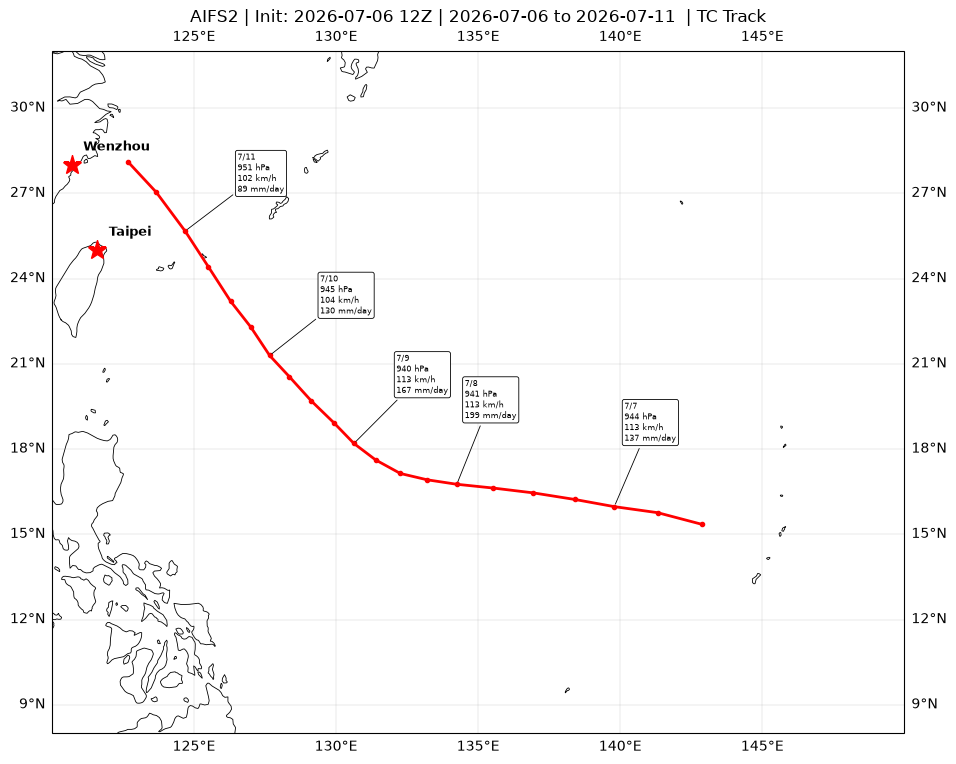

In [16]:
fig = plt.figure(figsize=(11, 11))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(TRACK_EXTENT, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)

ax.plot(track_aifs_df.tclon, track_aifs_df.tclat, "-o", color="red", lw=2.0, ms=3,
        transform=ccrs.PlateCarree())

# one callout per day (00Z marker): peak intensity (min MSLP, max wind) + that day's precip
# at the storm center
day_of = np.array([(START_TIME + timedelta(hours=int(h))).date() for h in track_aifs_df.lead_time_h])
lons = track_aifs_df.tclon.values; lats = track_aifs_df.tclat.values; n = len(track_aifs_df)
transform = ccrs.PlateCarree()._as_mpl_transform(ax)
R = 46   # leader-line length (points)
for idx, (_, r) in enumerate(track_aifs_df.iterrows()):
    valid = START_TIME + timedelta(hours=int(r.lead_time_h))
    if valid.hour != 0:                        # daily cadence: anchor at 00Z markers only
        continue
    day = valid.date()
    day_rows = track_aifs_df[day_of == day]
    mslp_min = day_rows.tcmsl_hPa.min()
    wind_max = day_rows.tcw10m_ms.max() * MS_TO_KMH
    field = daily_precip_mm(dsA, day)
    iy = int(np.abs(LAT - r.tclat).argmin()); ix = int(np.abs(LON - r.tclon).argmin())
    p_day = float(field[iy, ix]) if field is not None else 0.0
    label = f"{valid:%-m/%-d}\n{mslp_min:.0f} hPa\n{wind_max:.0f} km/h\n{p_day:.0f} mm/day"
    # offset perpendicular to the track heading, ocean side, so nothing sits on the track
    a = max(idx - 1, 0); b = min(idx + 1, n - 1)
    hx = lons[b] - lons[a]; hy = lats[b] - lats[a]
    px, py = hy, -hx                           # right-hand perpendicular to the heading
    nrm = (px * px + py * py) ** 0.5 or 1.0
    dx, dy = px / nrm * R, py / nrm * R
    ax.annotate(
        label, xy=(r.tclon, r.tclat), xycoords=transform,
        xytext=(dx, dy), textcoords="offset points",
        fontsize=6, ha="left" if dx >= 0 else "right",
        va="bottom" if dy >= 0 else "top", annotation_clip=False,
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", lw=0.6),
        arrowprops=dict(arrowstyle="-", color="black", lw=0.6),
    )
mark_cities(ax)

ax.set_title(fig_title("AIFS2", FCST_WINDOW) + "  | TC Track")
fig.savefig(FIG_DIR / "track_aifs.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** the red line is the AIFS2 storm center every 6 hours. Each box is anchored at a 00 UTC position and lists the date, that day's lowest pressure (hPa) and highest 10 m wind (km/h) along the AIFS2 track, and that day's rain (mm) at the storm center from the AIFS2 daily map. Look at how the storm's intensity changes as it nears the coast.

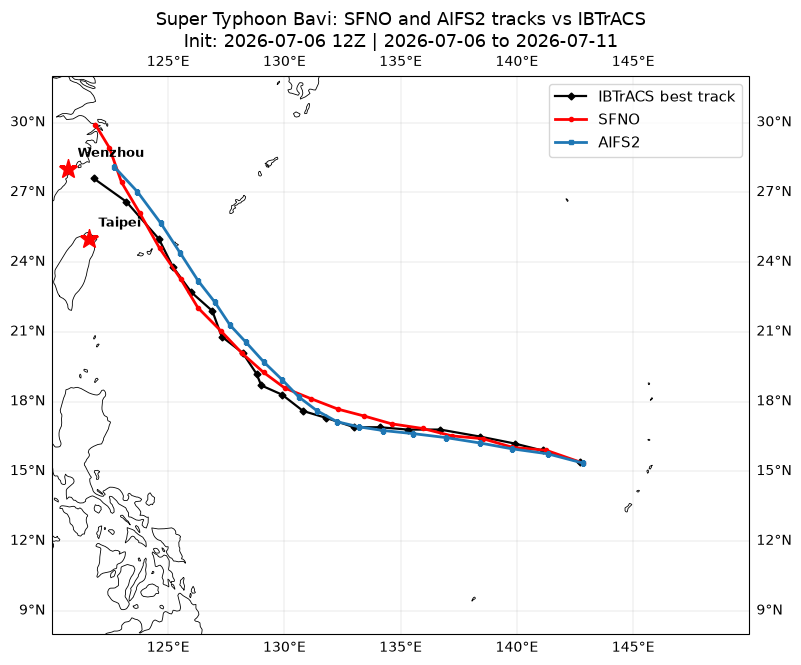

In [17]:
fig = plt.figure(figsize=(9, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(TRACK_EXTENT, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4)

# observed IBTrACS best track over the forecast period (6-hourly fixes), drawn first so the model tracks sit on top
best = load_best_track("Bavi", 2026, cache_dir=OUT_DIR / "ibtracs")
observed = best[best["valid_time"].between(pd.Timestamp(START_TIME), pd.Timestamp(VALID_TIMES[-1]))]
ax.plot(observed.lon, observed.lat, "-D", color="black", lw=1.6, ms=3.5, label="IBTrACS best track",
        transform=ccrs.PlateCarree())

# two model tracks, no info boxes — legend distinguishes them
ax.plot(track_df.tclon, track_df.tclat, "-o", color="red", lw=2.0, ms=3,
        label="SFNO", transform=ccrs.PlateCarree())
ax.plot(track_aifs_df.tclon, track_aifs_df.tclat, "-s", color="tab:blue", lw=2.0, ms=3,
        label="AIFS2", transform=ccrs.PlateCarree())
mark_cities(ax)
ax.legend(loc="upper right", fontsize=11)

ax.set_title("Super Typhoon Bavi: SFNO and AIFS2 tracks vs IBTrACS\n"
             f"Init: {START_TIME:%Y-%m-%d %HZ} | {FCST_WINDOW}", fontsize=13)
fig.savefig(FIG_DIR / "track_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** red circles are the SFNO track and blue squares the AIFS2 track, both from the same initial state and the same tracker, so the gap between them is a measure of how much the two models disagree. The black line is the IBTrACS best track over the same period, so the gap between a colored track and the black one is that model's position error (scored for SFNO in section 8). Look at where each track meets the coast relative to Wenzhou.

## 6 · 10 m wind

The strongest 10 m wind at each point over the forecast, and the wind at the expected landfall time, AIFS2 beside GraphCast. Wind near the surface is what drives coastal damage and storm surge.

peak 10 m wind: 2026-07-06 (161 km/h)


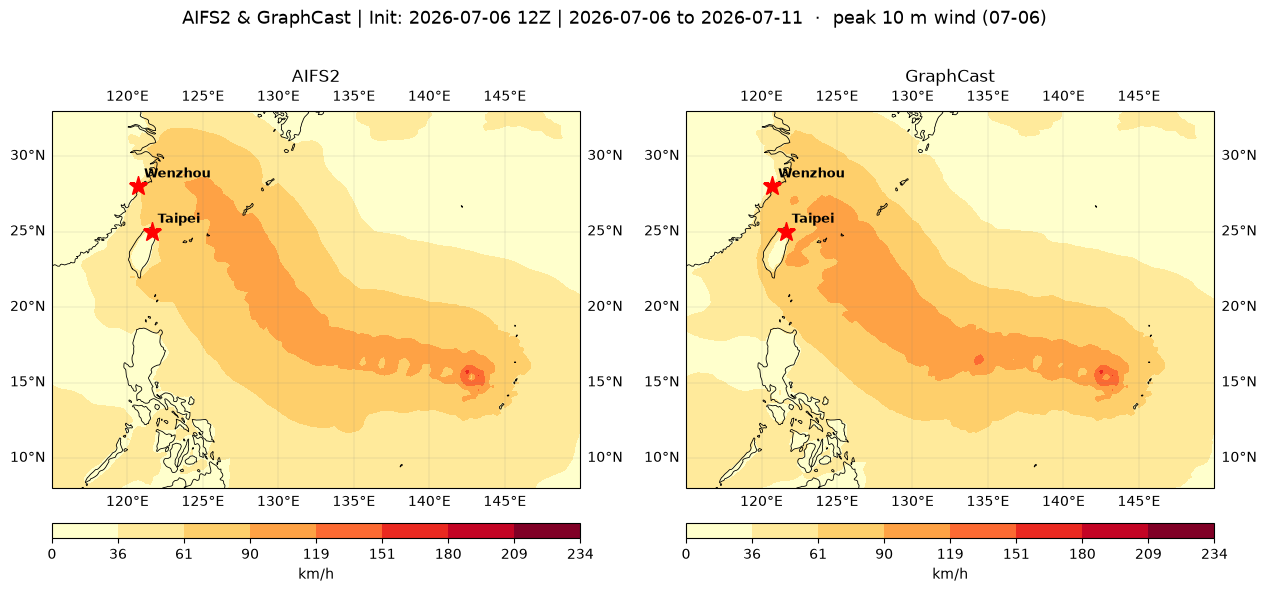

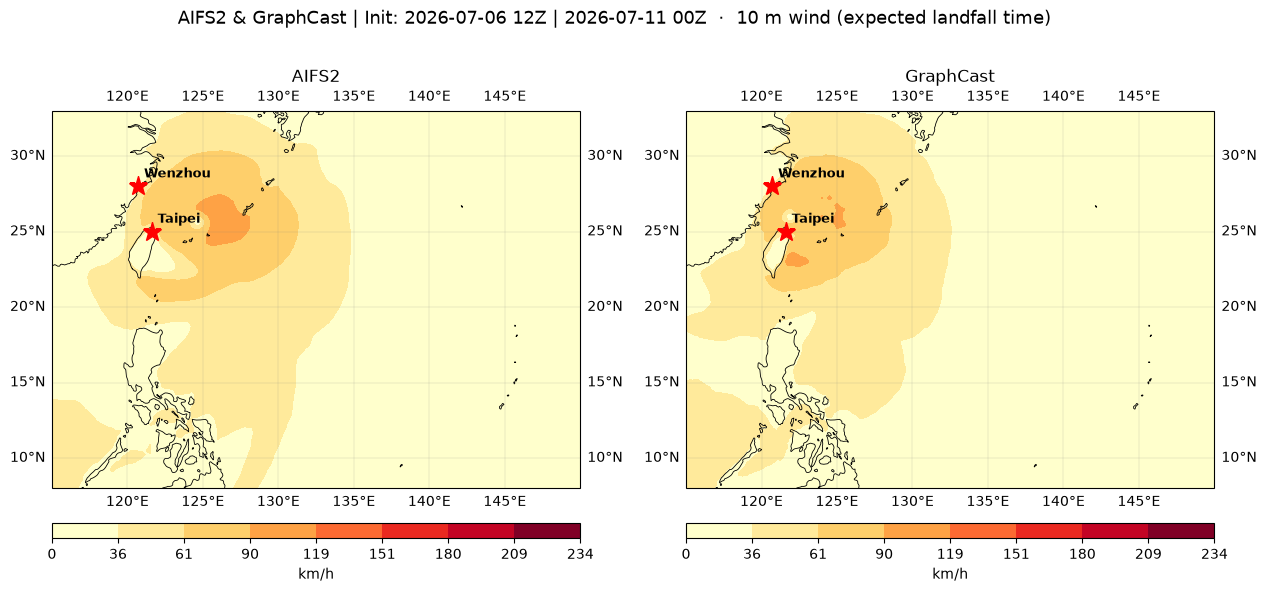

In [18]:
# day of the domain-peak 10 m wind (either model) -> flag it in the peak-wind figure name
def stepwise_domain_peak(ds):
    """Highest 10 m wind (km/h) inside PRECIP_EXTENT at each lead time."""
    w = wind_speed(ds)                      # (lead, lat, lon), computed once
    return np.array([domain_max(w[s]) for s in range(w.shape[0])])
sp = np.maximum(stepwise_domain_peak(dsA), stepwise_domain_peak(dsG))
peak_wind_day = VALID_TIMES[int(np.argmax(sp))].date()
print("peak 10 m wind:", peak_wind_day, f"({sp.max():.0f} km/h)")

plot_comparison(peakA, peakG, LON, LAT, WIND_LEVELS, plt.cm.YlOrRd,
                fig_title("AIFS2 & GraphCast", FCST_WINDOW) + f"  ·  peak 10 m wind ({peak_wind_day:%m-%d})",
                FIG_DIR / f"wind_peak_{peak_wind_day}_max.png", units="km/h")

plot_comparison(wind_at(dsA, LANDFALL), wind_at(dsG, LANDFALL), LON, LAT, WIND_LEVELS, plt.cm.YlOrRd,
                fig_title("AIFS2 & GraphCast", f"{LANDFALL:%Y-%m-%d %HZ}") + "  ·  10 m wind (expected landfall time)",
                FIG_DIR / "wind_landfall.png", units="km/h")

**How to read this:** colors are 10 m wind speed in km/h; the band edges are the thresholds 10, 17 (gale), 25, 33 (typhoon), 42, 50, 58 and 65 m/s converted to km/h. The peak-wind map takes the maximum over all lead times, including the initial analysis, and its file name carries the date of the domain-wide peak; the landfall map is valid at the expected landfall time set in the configuration, not at the observed one, so the storm is still offshore in it. Look at how far typhoon-force winds reach toward Wenzhou in each model.

## 7 · Forecast at Wenzhou

A short text summary for the landfall target: the SFNO storm's minimum pressure and peak wind, its closest approach to Wenzhou, and the storm-total rain and peak wind at the Wenzhou grid cell in AIFS2 and GraphCast. Section 8 checks the track part of this against observations.

In [19]:
# ---- concise summary at Wenzhou ----
imin = int(track_df.tcmsl_hPa.idxmin())
imax = int(track_df.tcw10m_ms.idxmax())
print(f"SFNO/Wu-Duan track: min MSLP {track_df.tcmsl_hPa.min():.0f} hPa "
      f"@ +{track_df.loc[imin,'lead_time_h']:.0f} h; peak 10 m wind {track_df.tcw10m_ms.max() * MS_TO_KMH:.0f} km/h "
      f"@ +{track_df.loc[imax,'lead_time_h']:.0f} h  (+0 h is the IFS analysis, not a forecast)")
closest = track_df.assign(d=haversine_km(track_df.tclat, track_df.tclon, *WENZHOU)).sort_values("d").iloc[0]
print(f"Closest approach to Wenzhou: {closest.d:.0f} km @ +{closest.lead_time_h:.0f} h "
      f"(valid {VALID_TIMES[int(closest.lead_time_h) // STEP_HOURS]:%Y-%m-%d %HZ})")

iy = int(np.abs(LAT - WENZHOU[0]).argmin()); ix = int(np.abs(LON - WENZHOU[1]).argmin())
print(f"Storm-total precip at Wenzhou grid cell:  AIFS2 {totalA[iy,ix]:.0f} mm | GraphCast {totalG[iy,ix]:.0f} mm")
print(f"Peak 10 m wind at Wenzhou grid cell:      AIFS2 {peakA[iy,ix]:.0f} km/h | GraphCast {peakG[iy,ix]:.0f} km/h")

SFNO/Wu-Duan track: min MSLP 942 hPa @ +0 h; peak 10 m wind 161 km/h @ +0 h  (+0 h is the IFS analysis, not a forecast)
Closest approach to Wenzhou: 201 km @ +114 h (valid 2026-07-11 06Z)
Storm-total precip at Wenzhou grid cell:  AIFS2 52 mm | GraphCast 112 mm
Peak 10 m wind at Wenzhou grid cell:      AIFS2 41 km/h | GraphCast 41 km/h


## 8 · Verify against the IBTrACS best track

IBTrACS (NOAA NCEI's International Best Track Archive for Climate Stewardship) collects the warning agencies' best tracks and is the observational truth used here. The SFNO / Wu–Duan track is compared with it at every common 6-hourly time: position error is the great-circle distance between the two storm centers, and MSLP error is the forecast minimum pressure minus the IBTrACS pressure (JTWC's value, with the WMO agency's as fallback). The first table keeps every 12 hours. The second compares the closest approach to Wenzhou like for like: the forecast track against the best track clipped to the same forecast window, with the closest approach over the whole best track alongside as context.

**Caveats.** IBTrACS positions and pressures are agency analyses (JTWC/WMO), not direct measurements, and the Wu–Duan tracker defines the storm center differently (a vorticity core on a 0.25° grid), so some position error is definitional. For recent seasons IBTrACS holds provisional tracks (real-time operational estimates) until the agencies release their final best tracks, so the scores can change when the file is updated. A 0.25° model cannot resolve the inner core of an intense typhoon, so large positive MSLP errors (model storm too weak) are expected. Both tracks are compared at 6-hourly fixes only; IBTrACS's 3-hourly positions are interpolated and are not used. A typhoon moves tens of kilometres per hour, so a closest approach read from 6-hourly fixes can be off by tens of kilometres and its time by up to 3 hours. The best-track file is downloaded once and cached in `outputs/bavi/ibtracs/`; delete that folder to fetch a fresh copy.

In [20]:
best = load_best_track("Bavi", 2026, cache_dir=OUT_DIR / "ibtracs")
errors = verify_track(track_df, best, START_TIME)
errors_every_12h = errors[errors["Lead (h)"] % 12 == 0].reset_index(drop=True)
errors_every_12h.to_csv(RESULTS_DIR / "bavi_track_metrics.csv", index=False)

fc = track_df.assign(valid_time=pd.Timestamp(START_TIME) + pd.to_timedelta(track_df["lead_time_h"], unit="h"))
fc_end = fc["valid_time"].max()  # last forecast fix of the tracked storm


def closest_approach(df, lat_col, lon_col):
    """Distance (km) and UTC time of a track's closest approach to Wenzhou."""
    dist = np.asarray(haversine_km(df[lat_col].values, df[lon_col].values, *WENZHOU))
    i = int(np.argmin(dist))
    return float(dist[i]), df["valid_time"].iloc[i]


def utc(t):
    """Timestamp as 'YYYY-MM-DD HH:MM' (UTC)."""
    return t.strftime("%Y-%m-%d %H:%M")


# Like for like: the best track is clipped to the period the forecast covers. The whole best track is context.
fc_km, fc_time = closest_approach(fc, "tclat", "tclon")
win_km, win_time = closest_approach(best[best["valid_time"].between(pd.Timestamp(START_TIME), fc_end)], "lat", "lon")
full_km, full_time = closest_approach(best, "lat", "lon")
# Censored: the forecast storm is still closing in at its last fix while the real storm passed closest later,
# so the forecast's own closest approach, and its timing, lie beyond the forecast.
censored = fc_time == fc_end and full_time > fc_end
timing_h = float("nan") if censored else round((fc_time - full_time) / pd.Timedelta(hours=1))

landfall_df = pd.DataFrame([{
    "Forecast closest approach (km)": round(fc_km),
    "Observed closest approach, forecast window (km)": round(win_km),
    "Forecast time (UTC)": utc(fc_time),
    "Observed time, forecast window (UTC)": utc(win_time),
    "Last forecast fix (UTC)": utc(fc_end),
    "Observed closest approach, full best track (km)": round(full_km),
    "Observed time, full best track (UTC)": utc(full_time),
    "Timing error (h)": timing_h,
}])
landfall_df.to_csv(RESULTS_DIR / "bavi_landfall_metrics.csv", index=False, na_rep="n/a")
print("SFNO / Wu-Duan track vs IBTrACS best track (every 12 h)\n")
print(errors_every_12h.to_string(index=False))
print("\nClosest approach to Wenzhou\n")
print(landfall_df.T.to_string(header=False, na_rep="n/a"))
if full_time > fc_end:
    print("\nThe best track passes closest to Wenzhou after the last forecast fix, so compare the forecast with the "
          "forecast-window columns; the full-best-track columns are context.")
if censored:
    print("Timing error is n/a: the forecast storm is still approaching at its last fix, so its closest approach is not known.")

SFNO / Wu-Duan track vs IBTrACS best track (every 12 h)

 Lead (h)  Position error (km)  MSLP error (hPa)
        0                 18.0              24.2
       12                 21.0              21.9
       24                 61.0              24.6
       36                 56.0              29.2
       48                 69.0              19.1
       60                 34.0               5.3
       72                117.0              -2.1
       84                174.0              -8.7
       96                253.0               0.4
      108                315.0              13.9
      120                258.0              25.8

Closest approach to Wenzhou

Forecast closest approach (km)                                201
Observed closest approach, forecast window (km)               117
Forecast time (UTC)                              2026-07-11 06:00
Observed time, forecast window (UTC)             2026-07-11 12:00
Last forecast fix (UTC)                          2026-07-11 1

**How to read this:** in the first table each row is a lead time (lead 0 is the initial analysis, not a forecast, so its errors show how closely the analysis agrees with the best track); a smaller position error means a closer track, and the sign of the MSLP error shows whether the model storm is too weak (+) or too deep (−). The second table is printed one column per line. Compare "Forecast closest approach (km)" and "Forecast time (UTC)" with the two "forecast window" columns: both tracks are limited to the same period, which ends at "Last forecast fix (UTC)". The two "full best track" columns show how close and when the real storm passed over its whole life; when "Observed time, full best track (UTC)" is later than "Last forecast fix (UTC)", the forecast cannot reach that pass. "Timing error (h)" is the forecast time minus the full-track observed time (negative: the forecast storm is closest earlier). It is n/a when the forecast storm is still approaching at its last fix and the real storm passed closest later, because the forecast's own closest approach is then unknown. Both tables are saved as CSV files in `docs/results/`.

## Summary

- **SFNO track map** (`figures/track.png`): where the SFNO / Wu–Duan storm center goes relative to Wenzhou and Taipei.
- **Intensity series** (`figures/intensity.png`): how the model storm's minimum pressure and maximum wind evolve; compare its depth with the IBTrACS pressures in section 8.
- **Daily and storm-total rain maps** (`figures/precip_daily_*.png`, `figures/precip_total.png`): where AIFS2 and GraphCast put the heaviest rain, and whether they agree.
- **Rain along the track** (table in section 4): how much rain each model gives at the SFNO storm center every 6 hours.
- **AIFS2 annotated track** (`figures/track_aifs.png`): the AIFS2 storm's daily intensity and the rain at its center.
- **Track comparison** (`figures/track_comparison.png`): whether SFNO and AIFS2 agree on the path and on where it meets the coast.
- **Peak and landfall wind maps** (`figures/wind_peak_*_max.png`, `figures/wind_landfall.png`): where strong winds reach the coast in each model.
- **Forecast at Wenzhou** (section 7): the forecast's minimum pressure, peak wind, closest approach, and the rain and wind at Wenzhou.
- **IBTrACS verification** (section 8): how far the SFNO track is from the best track at each lead time, how wrong its pressure is, and how its closest approach to Wenzhou compares with the observed one.

The verification tables are saved as `docs/results/bavi_track_metrics.csv` and `docs/results/bavi_landfall_metrics.csv`. The numbers change with every run, so they live in those tables, not here.